In [ ]:
import pandas as pd
import numpy as np
import re
!pip install pymorphy2
import pymorphy2


RANDOM_STATE = 42

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 25.3 MB/s eta 0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13706 sha256=23c54b9257012da57f23f6d1659952a207541b44bd9b49d35fb77c05a2608616
  Stored in directory: /root/.cache/pip/wheels/fc/ab/d4/5da2067ac95b36618c629a5f93f809425700506f72c9732fac
Successfully built docopt


### Загрузка датасета

In [ ]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/3.csv              
  inflating: data/1.csv              
  inflating: data/2.csv              


#### 3. датасет 3

In [ ]:
df = pd.read_csv('data/3.csv')
print(df.shape)

(13833, 2)


In [ ]:
LABELS_COUNT = 2

#### mini eda, detailed: https://github.com/hse-toxic/toxiccc/blob/pikabu/eda/nlp_first_iteration.ipynb

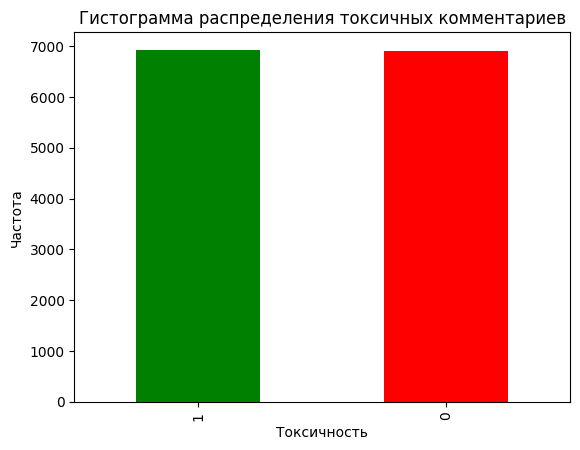

In [ ]:
import matplotlib.pyplot as plt


df['toxic'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

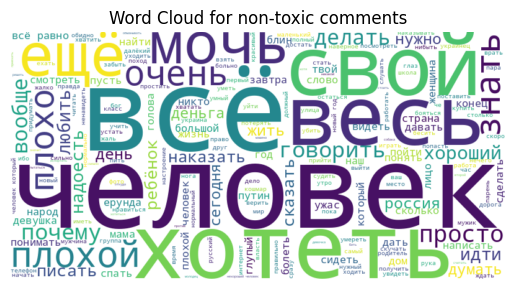

In [ ]:
from wordcloud import WordCloud
from functools import reduce


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] == 0.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for non-toxic comments')
plt.show()

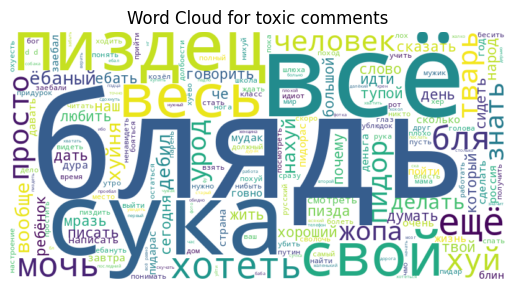

In [ ]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] == 1.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments')
plt.show()

#### train test split

In [ ]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.33, random_state=RANDOM_STATE)
y_train = df_train['toxic']
y_true = df_test['toxic']

## Baseline

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns


metrics = dict()

def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

    if title:
        metrics[title] = dict()
        metrics[title]['accuracy'] = accuracy
        metrics[title]['precision'] = precision
        metrics[title]['recall'] = recall
        metrics[title]['f1'] = f1

### 1. Модель с константным предсказанием

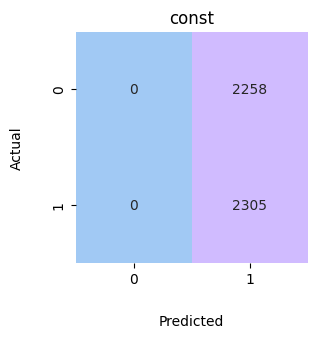

accuracy:	0.505150120534736
precision:	0.25517664427625825
recall:		0.505150120534736
f1:		0.33907135347483003


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
y_pred = np.full(y_true.shape, 1)
get_metrics(y_true, y_pred, 'const')

### 2. Модель со случайным предсказанием

In [ ]:
class BaseLineModel():
    def __init__(self, predict_function):
        self.predict_function = predict_function

    def predict(self, X):
        return np.array(list(map(self.predict_function, X)))

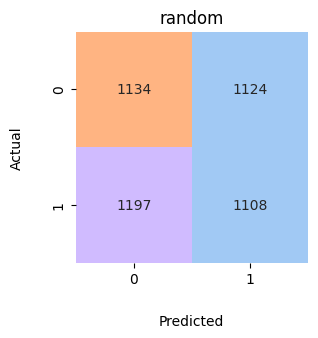

accuracy:	0.4913434144203375
precision:	0.491502265557959
recall:		0.4913434144203375
f1:		0.4912970447463165


In [ ]:
def random_prediction(comment):
    return np.random.randint(0, LABELS_COUNT)


random_model = BaseLineModel(random_prediction)
y_pred = random_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'random')

### 3. Lexicon-based

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
toxic_dict = dict()
for i in range(1, LABELS_COUNT):
    comments = " ".join(df_train[df_train['toxic'] == i]['comment'].tolist())
    comments_tokens = word_tokenize(comments)
    text = nltk.Text(comments_tokens)
    text = [word for word in text if word not in ru_stopwords]
    f_dist = FreqDist(text)
    toxic_dict[i] = set(map(lambda x: x[0], f_dist.most_common(20)))
print(toxic_dict)

{1: {'нахуй', 'сука', 'знать', 'хуйня', 'хотеть', 'пидор', 'ещё', 'мочь', 'блядь', 'бля', 'человек', 'всё', 'весь', 'свой', 'тварь', 'делать', 'жопа', 'пиздец', 'хуй', 'просто'}}


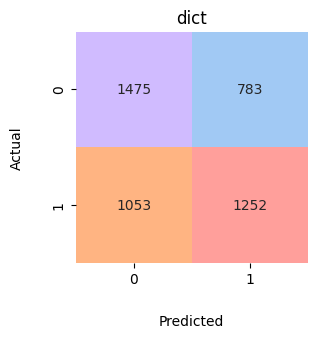

accuracy:	0.5976331360946746
precision:	0.5995129127431952
recall:		0.5976331360946746
f1:		0.5964667873896508


In [ ]:
def dict_prediction(comment):
    for word in comment.split(' '):
        for label in toxic_dict:
            if word in toxic_dict[label]:
                return label
    return 0


dict_model = BaseLineModel(dict_prediction)
y_pred = dict_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'dict')

### 4. Rule-based

In [ ]:
!pip install fkscore
import fkscore

In [ ]:
df_test_copy = df_test.copy()
df_test_copy['fkscore'] = df_test_copy['comment'].apply(lambda comment: fkscore.fkscore(comment).score['readability'])
print(df_test_copy[df_test_copy['toxic'] == 0]['fkscore'].describe())
print()
print(df_test_copy[df_test_copy['toxic'] != 0]['fkscore'].describe())

count    2258.000000
mean      117.182195
std         2.835184
min        96.025000
25%       116.145000
50%       118.175000
75%       119.190000
max       121.220000
Name: fkscore, dtype: float64

count    2305.000000
mean      115.888066
std         3.055605
min        88.905000
25%       114.115000
50%       116.145000
75%       118.175000
max       134.080000
Name: fkscore, dtype: float64


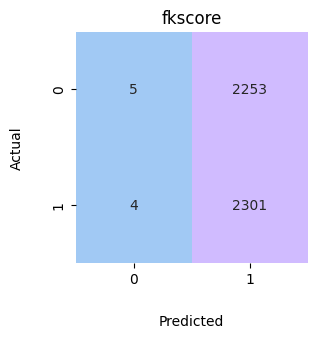

accuracy:	0.5053692746000439
precision:	0.5301538476937957
recall:		0.5053692746000439
f1:		0.341109922119548


In [ ]:
def fkscore_prediction(comment):
    score = fkscore.fkscore(comment).score
    return score['readability'] > 102


fkscore_model = BaseLineModel(fkscore_prediction)
y_pred = fkscore_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'fkscore')

### 5. BoW

#### 5.1 Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

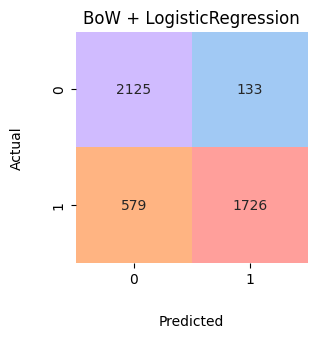

accuracy:	0.843962305500767
precision:	0.8578987917290148
recall:		0.843962305500767
f1:		0.8426183966984363


In [ ]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + LogisticRegression')

#### 5.2 SVC

In [ ]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

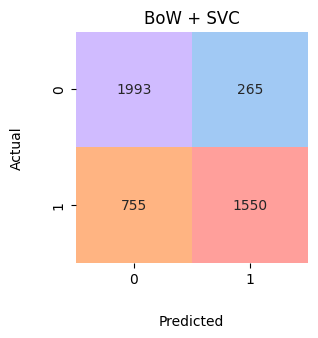

accuracy:	0.7764628533859304
precision:	0.7902876358154705
recall:		0.7764628533859304
f1:		0.7741101810385959


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + SVC')

### 6. TF-IDF

#### 6.1 LogisticRegression

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


vectorizer = TfidfVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

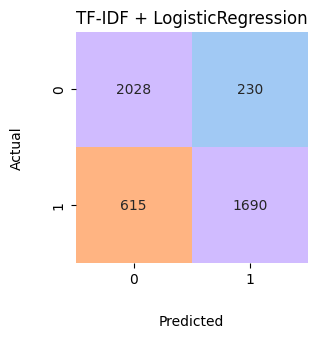

accuracy:	0.8148148148148148
precision:	0.8243405449054806
recall:		0.8148148148148148
f1:		0.8136510311576625


In [ ]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + LogisticRegression')

#### 6.2 SVC

In [ ]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

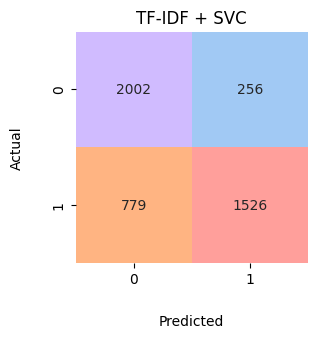

accuracy:	0.7731755424063116
precision:	0.78881582774298
recall:		0.7731755424063116
f1:		0.7704336555699756


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + SVC')

#### 6.3 GradientBoosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier


clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

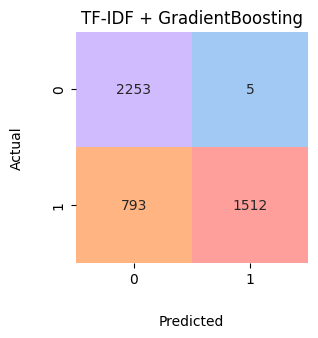

accuracy:	0.8251150558842867
precision:	0.8695051099175968
recall:		0.8251150558842867
f1:		0.8200776998201293


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + GradientBoosting')

### 7. N-grams + Naive Byas

In [ ]:
from sklearn.naive_bayes import MultinomialNB


vectorizer = CountVectorizer(ngram_range=(1, 2))
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

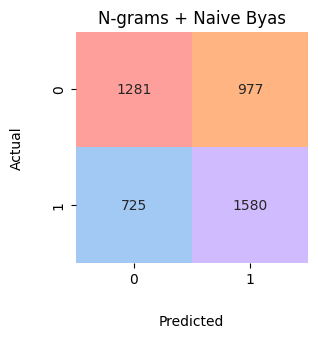

accuracy:	0.6269997808459347
precision:	0.6281414646691248
recall:		0.6269997808459347
f1:		0.6256441274523844


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'N-grams + Naive Byas')

### 8. Word2Vec

#### 8.1 LogisticRegression

In [ ]:
from gensim.models import Word2Vec

VECTOR_SIZE = 100
sentences = [sentence.split() for sentence in df_train['comment']]
w2v_model = Word2Vec(sentences, vector_size=VECTOR_SIZE, window=5, min_count=5, workers=4)

In [ ]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    if len(words_vecs) == 0:
        return np.zeros(VECTOR_SIZE)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

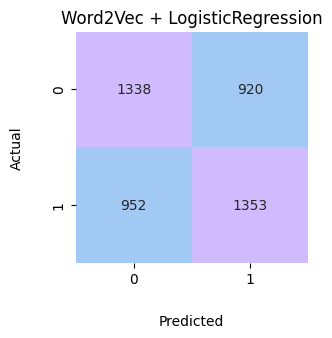

accuracy:	0.5897435897435898
precision:	0.5898205152342866
recall:		0.5897435897435898
f1:		0.5897530477666518


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + LogisticRegression')

#### 8.2 KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

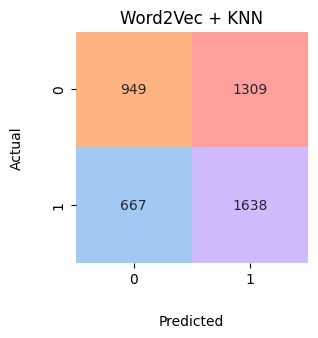

accuracy:	0.5669515669515669
precision:	0.5713740926135978
recall:		0.5669515669515669
f1:		0.5575368690781419


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + KNN')

#### 8.3 SVC

In [ ]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

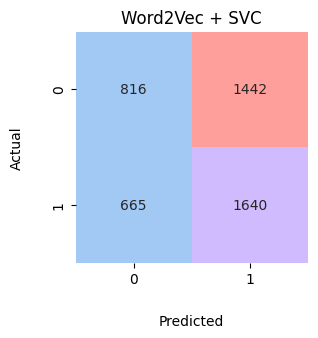

accuracy:	0.5382423843962305
precision:	0.5414534172688215
recall:		0.5382423843962305
f1:		0.5235646218791309


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + SVC')

#### 8.4 GradientBoosting

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

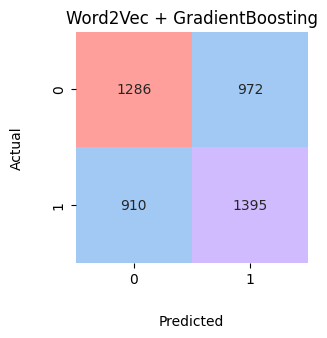

accuracy:	0.5875520490905106
precision:	0.5875011852877962
recall:		0.5875520490905106
f1:		0.5874181016896324


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + GradientBoosting')

### 9. GloVe

#### 9.1 LogisticRegression

In [ ]:
!pip install navec
!wget https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

--2024-12-11 18:12:15--  https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53012480 (51M) [application/x-tar]
Saving to: ‘navec_hudlit_v1_12B_500K_300d_100q.tar.2’

navec_hudlit_v1_12B 100%[===================>]  50.56M  16.4MB/s    in 3.6s    

2024-12-11 18:12:19 (14.1 MB/s) - ‘navec_hudlit_v1_12B_500K_300d_100q.tar.2’ saved [53012480/53012480]



In [ ]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [ ]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [navec[word] for word in words if word in navec]
    if len(words_vecs) == 0:
        return np.zeros(300)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

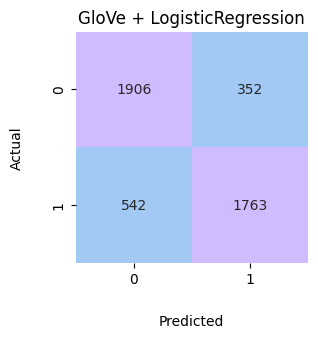

accuracy:	0.8040762656147271
precision:	0.8063653833125287
recall:		0.8040762656147271
f1:		0.803820346634661


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + LogisticRegression')

#### 9.2 KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

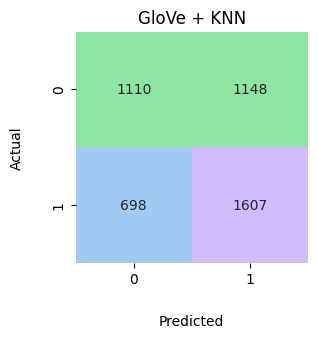

accuracy:	0.5954415954415955
precision:	0.5984627954216635
recall:		0.5954415954415955
f1:		0.5910438282067274


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + KNN')

#### 9.3 SVC

In [ ]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

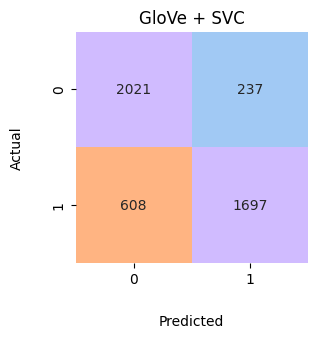

accuracy:	0.8148148148148148
precision:	0.8236546391280223
recall:		0.8148148148148148
f1:		0.8137402826888386


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + SVC')

#### 9.4 GradientBoosting

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

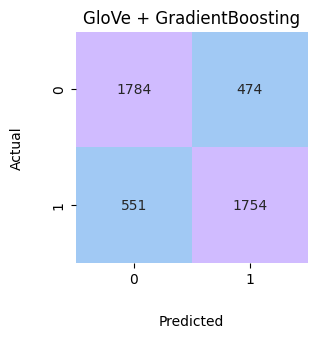

accuracy:	0.7753670830593907
precision:	0.7757590430274559
recall:		0.7753670830593907
f1:		0.7753421598932796


In [ ]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + GradientBoosting')

### Вывод

In [ ]:
metrics_df = pd.DataFrame(metrics).T
cols = metrics_df.columns.tolist()
cols = cols[-1:] + cols[:-1]
metrics_df = metrics_df[cols].sort_values(by=['f1'], ascending=False)
metrics_df

,f1,accuracy,precision,recall
BoW + LogisticRegression,0.842618,0.843962,0.857899,0.843962
TF-IDF + GradientBoosting,0.820078,0.825115,0.869505,0.825115
GloVe + SVC,0.813740,0.814815,0.823655,0.814815
TF-IDF + LogisticRegression,0.813651,0.814815,0.824341,0.814815
GloVe + LogisticRegression,0.803820,0.804076,0.806365,0.804076
GloVe + GradientBoosting,0.775342,0.775367,0.775759,0.775367
BoW + SVC,0.774110,0.776463,0.790288,0.776463
TF-IDF + SVC,0.770434,0.773176,0.788816,0.773176
N-grams + Naive Byas,0.625644,0.627000,0.628141,0.627000
dict,0.596467,0.597633,0.599513,0.597633


Из baseline моделей наилучшие результаты показали GloVe + SVC, TF-IDF + GradientBoosting и BoW + LogisticRegression. Стоит отметить, что BoW + LogisticRegression один из самых быстрых методов и при этом находится среди лучших результатов.

